# A/B-эксперимент `new_checkout_button`: от событий до BI-дашборда

Ноутбук проходит путь аналитика целиком и сохраняет выводы ячеек, так что результат виден
без запуска.

1. собрать событийное хранилище (users / assignments / sessions / orders);
2. вытащить витрины **через SQL**, а не через pandas: так же, как это делается на проде;
3. проверить сплит (SRM) и посчитать MDE **до** того, как смотреть на результат;
4. посчитать эффект тремя способами и понять, почему они расходятся;
5. собрать аддитивную витрину и дашборд, который дальше уезжает в Yandex DataLens.

Истинный эффект, заложенный в симуляцию: **+8 % к P(заказ | сессия)**. Это нужно, чтобы
проверять не только «значимо / не значимо», но и попали ли мы в настоящее значение.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

from ablab.db import build_warehouse, run_sql
from ablab.population import sample_population
from ablab import stats as S

SEED, N_USERS, PRE_DAYS, EXP_DAYS = 7, 60_000, 28, 14
EXPERIMENT, TRUE_UPLIFT = "new_checkout_button", 0.08

rng = np.random.default_rng(SEED)
(ROOT / "data").mkdir(exist_ok=True)
DB = ROOT / "data" / "warehouse.sqlite"

pop = sample_population(N_USERS, rng)
build_warehouse(DB, pop, EXPERIMENT, PRE_DAYS, EXP_DAYS, TRUE_UPLIFT, rng)

import sqlite3
with sqlite3.connect(DB) as con:
    counts = pd.read_sql_query(
        "SELECT 'users' t, COUNT(*) n FROM users UNION ALL "
        "SELECT 'assignments', COUNT(*) FROM assignments UNION ALL "
        "SELECT 'sessions', COUNT(*) FROM sessions UNION ALL "
        "SELECT 'orders', COUNT(*) FROM orders", con)
print(counts.to_string(index=False))
print(f"\nразмер базы: {DB.stat().st_size / 1e6:.1f} МБ")

          t       n
      users   60000
assignments   60000
   sessions 2005753
     orders   68145

размер базы: 61.8 МБ


## 1. Sanity-проверка: Sample Ratio Mismatch

Первое, что смотрит аналитик, — совпал ли фактический сплит с задуманным. Если нет, дальше
считать нечего: любая разница метрик может объясняться тем, что группы собраны по-разному
(типичные причины — редирект, который теряет часть трафика, или фильтр, применённый только
к одной ветке).

Критерий — хи-квадрат на согласие с долями 50/50. Порог берут жёсткий, `p < 0.001`, а не 0.05:
проверка выполняется на каждом эксперименте, и при пороге 0.05 каждый двадцатый здоровый
эксперимент признавался бы сломанным.

In [2]:
srm = run_sql(DB, ROOT / "sql" / "srm.sql", experiment=EXPERIMENT)
n_c, n_t = srm.set_index("variant").loc[["control", "treatment"], "n_users"]
p_srm = S.srm_test(int(n_c), int(n_t))

print(srm.to_string(index=False))
print(f"\nфактическая доля treatment: {n_t / (n_c + n_t):.4f}")
print(f"хи-квадрат p = {p_srm:.3f} -> {'сплит здоров' if p_srm > 1e-3 else 'SRM, результаты невалидны'}")

  variant  n_users
  control    30001
treatment    29999

фактическая доля treatment: 0.5000
хи-квадрат p = 0.993 -> сплит здоров


## 2. Витрина на пользователя: SQL, а не pandas

Единица рандомизации — пользователь, значит и строка витрины — пользователь. Два момента
в запросе важнее остальных:

* **`LEFT JOIN`, а не `JOIN`.** Пользователи, которые попали в эксперимент и не сделали ничего,
  остаются в выборке с нулями. Если их выкинуть, сравнение поедет: новая кнопка могла как раз
  и влиять на то, вернётся человек вообще или нет. Это разница между intent-to-treat и
  per-protocol, и в A/B по умолчанию считают ITT.
* **предпериод в том же запросе.** Колонки `*_pre` считаются по дням `day < 0`, то есть до
  рандомизации. Они понадобятся в разделе 4 для снижения дисперсии.

In [3]:
print((ROOT / "sql" / "user_metrics.sql").read_text(encoding="utf-8"))

-- Per-user metrics for one experiment: experiment period (day >= 0) and pre-period (day < 0).
-- Randomisation unit = user, so every row is one independent observation.
-- LEFT JOINs keep users who were assigned but did nothing: dropping them would bias the comparison
-- (intent-to-treat).
WITH exp_users AS (
    SELECT a.user_id, a.variant, u.platform, u.region
    FROM assignments AS a
    JOIN users AS u USING (user_id)
    WHERE a.experiment = :experiment
),
s AS (
    SELECT user_id,
           SUM(CASE WHEN day >= 0 THEN 1 ELSE 0 END) AS sessions,
           SUM(CASE WHEN day <  0 THEN 1 ELSE 0 END) AS sessions_pre
    FROM sessions
    GROUP BY user_id
),
o AS (
    SELECT user_id,
           SUM(CASE WHEN day >= 0 THEN 1   ELSE 0 END) AS orders,
           SUM(CASE WHEN day >= 0 THEN gmv ELSE 0 END) AS gmv,
           SUM(CASE WHEN day <  0 THEN 1   ELSE 0 END) AS orders_pre,
           SUM(CASE WHEN day <  0 THEN gmv ELSE 0 END) AS gmv_pre,
           -- last 14 pre-period da

In [4]:
df = run_sql(DB, ROOT / "sql" / "user_metrics.sql", experiment=EXPERIMENT)
c, t = df[df.variant == "control"], df[df.variant == "treatment"]
print(f"строк: {len(df):,}   нулевых по GMV: {(df.gmv == 0).mean():.1%}")
df.head()

строк: 60,000   нулевых по GMV: 76.8%


,user_id,variant,platform,region,sessions,sessions_pre,orders,orders_pre,gmv,gmv_pre,gmv_hist14
0,0,control,web,regions,17,21,0,2,0.0,1394.86,660.00
1,1,control,android,regions,10,41,0,2,0.0,3683.59,664.45
2,2,control,ios,spb,2,8,0,0,0.0,0.00,0.00
3,3,treatment,android,regions,0,0,0,0,0.0,0.00,0.00
4,4,control,android,moscow,18,38,2,1,2684.4,3199.01,0.00


Распределение выручки — вот почему дальше всё устроено именно так.

count    60000.0
mean       911.9
std       2913.5
min          0.0
25%          0.0
50%          0.0
75%          0.0
max      96137.2

асимметрия: 6.8   доля выручки у верхнего 1 % пользователей: 23.5%


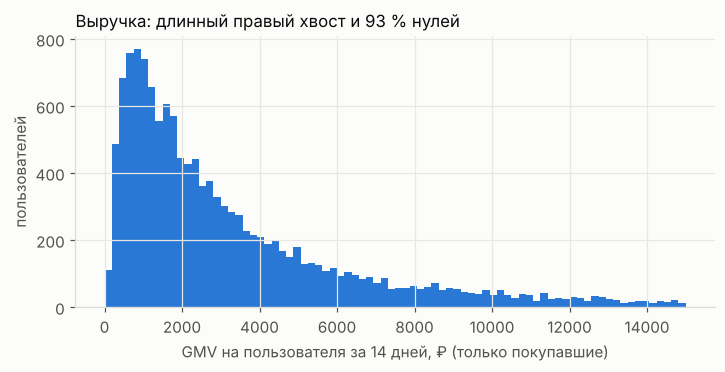

In [5]:
INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b2"
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": "#dcdbd5", "axes.grid": True, "grid.color": "#e8e7e1",
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "lines.linewidth": 2,
})

print(df.gmv.describe().round(1).to_string())
print(f"\nасимметрия: {df.gmv.skew():.1f}   доля выручки у верхнего 1 % пользователей: "
      f"{df.gmv.nlargest(len(df) // 100).sum() / df.gmv.sum():.1%}")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(df.loc[df.gmv > 0, "gmv"], bins=80, range=(0, 15000), color=BLUE)
ax.set_xlabel("GMV на пользователя за 14 дней, ₽ (только покупавшие)")
ax.set_ylabel("пользователей")
ax.set_title("Выручка: длинный правый хвост и 93 % нулей", loc="left")
plt.show()

Хвост тяжёлый, и из этого следуют три вещи, которые дальше встретятся по очереди:

* дисперсия большая → MDE плохой → нужен CUPED (раздел 4);
* средние по-прежнему нормальны по ЦПТ (n ~ 3·10⁴), поэтому t-тест применим, несмотря на
  ненормальность самой выручки — нормальность требуется от *среднего*, а не от наблюдений;
* ranksum-тесты вроде Манна–Уитни тут выглядят «мощнее», но проверяют не ту гипотезу:
  стохастическое доминирование, а не разность средних. Бизнес-решение принимается по деньгам,
  поэтому в разделе 4 они только для сравнения.

## 3. Дизайн: MDE до эксперимента

Расчёт мощности делается **до** просмотра результата и на исторических данных — здесь это
последние 14 дней предпериода, то есть «эксперимент такой же длины, но без воздействия».

$$\mathrm{MDE} = (z_{1-\alpha/2} + z_{\text{power}})\,\sigma\sqrt{\tfrac{2}{n}}$$

Смысл: эффект различим, когда он больше шума оценки. Корень из 2 — потому что разность двух
независимых средних, корень из n в знаменателе — обычное усреднение.

In [6]:
hist = df.gmv_hist14.values
sigma, base = hist.std(ddof=1), hist.mean()
n_grp = len(df) // 2

mde_abs = S.mde(sigma, n_grp)
print(f"σ = {sigma:,.0f} ₽,  среднее = {base:,.0f} ₽,  n = {n_grp:,} на группу")
print(f"MDE = {mde_abs:,.0f} ₽ = {100 * mde_abs / base:.1f} % (alpha 0.05, power 0.8)")
print(f"чтобы ловить +2 %, нужно {S.sample_size(sigma, 0.02 * base):,} пользователей на группу")

grid = pd.DataFrame({"n на группу": [5_000, 10_000, 30_000, 100_000, 300_000]})
grid["MDE, %"] = [100 * S.mde(sigma, n) / base for n in grid["n на группу"]]
grid["MDE с CUPED (R²=0.27), %"] = grid["MDE, %"] * np.sqrt(1 - 0.27)
grid.round(2)

σ = 2,911 ₽,  среднее = 876 ₽,  n = 30,000 на группу
MDE = 67 ₽ = 7.6 % (alpha 0.05, power 0.8)
чтобы ловить +2 %, нужно 433,557 пользователей на группу


,n на группу,"MDE, %","MDE с CUPED (R²=0.27), %"
0,5000,18.62,15.91
1,10000,13.17,11.25
2,30000,7.60,6.50
3,100000,4.16,3.56
4,300000,2.40,2.05


Истинный эффект в симуляции даёт около +5 % к выручке — он **меньше MDE** плоского t-теста
(7.6 %). То есть эксперимент на 60 тысячах пользователей недомощен, и обычный t-тест,
скорее всего, его не поймает. Это не беда дизайна, а причина для раздела 4: снижение
дисперсии — единственный способ выиграть мощность, не увеличивая выборку и не продлевая тест.

## 4. Эффект: четыре способа посчитать одно и то же

**Welch** — честная база: разность средних, неравные дисперсии.

**CUPED** (Deng et al., 2013) — это метод контрольных переменных из Монте-Карло:

$$y' = y - \theta\,(x - \mathbb{E}x), \qquad \theta = \frac{\mathrm{Cov}(y, x)}{\mathrm{Var}\,x},
\qquad \mathrm{Var}\,y' = \mathrm{Var}\,y\,(1 - \rho^2)$$

`x` — поведение пользователя *до* рандомизации, поэтому оно не зависит от группы и оценка
остаётся несмещённой; вычитается только предсказуемый «фон». Геометрически: проекция `y` на
линейную оболочку ковариат, в тесте остаётся ортогональный остаток. С несколькими ковариатами
это обычная регрессионная корректировка (Lin, 2013), и дисперсия падает на `R²`.

**Дельта-метод** — для ratio-метрик вида `сумма числителей / сумма знаменателей`. Это формула
распространения ошибок первого порядка:

$$\mathrm{Var}\!\left(\frac{\bar N}{\bar D}\right) \approx
\frac{\mathrm{Var}\,N - 2R\,\mathrm{Cov}(N, D) + R^2\,\mathrm{Var}\,D}{n\,\mu_D^2}$$

Независимы пары `(N_u, D_u)` по пользователям, а не отдельные сессии.

In [7]:
base_gmv, base_conv = c.gmv.mean(), (c.orders > 0).mean()
base_ratio = c.orders.sum() / c.sessions.sum()
COV = ["gmv_pre", "orders_pre", "sessions_pre"]

def row(metric, method, res, b):
    return {"метрика": metric, "метод": method, "эффект, %": 100 * res.effect / b,
            "CI 95 % низ": 100 * res.ci_low / b, "CI 95 % верх": 100 * res.ci_high / b,
            "p-value": res.pvalue}

rows = [row("GMV на пользователя", "Welch t-test", S.welch_ttest(c.gmv.values, t.gmv.values), base_gmv)]
r1, rho2 = S.cuped(c.gmv.values, t.gmv.values, c.gmv_pre.values, t.gmv_pre.values)
rows.append(row("GMV на пользователя", "CUPED, 1 ковариата", r1, base_gmv))
r3, r2_multi = S.cuped_multi(c.gmv.values, t.gmv.values, c[COV].values, t[COV].values)
rows.append(row("GMV на пользователя", "CUPED, 3 ковариаты", r3, base_gmv))
rows.append(row("GMV на пользователя", "Пуассоновский бутстрэп",
                S.poisson_bootstrap(c.gmv.values, t.gmv.values, 2000, rng), base_gmv))
rows.append(row("Конверсия в покупателя", "Welch t-test",
                S.welch_ttest((c.orders > 0).values.astype(float),
                              (t.orders > 0).values.astype(float)), base_conv))
rows.append(row("Заказы на сессию", "дельта-метод",
                S.ratio_delta(c.orders.values, c.sessions.values,
                              t.orders.values, t.sessions.values), base_ratio))
rows.append(row("Заказы на сессию", "наивный z-тест по сессиям (неверно)",
                S.ratio_naive(c.orders.values, c.sessions.values,
                              t.orders.values, t.sessions.values), base_ratio))
res = pd.DataFrame(rows)

print(f"снижение дисперсии: ρ² = {rho2:.3f} (1 ковариата), R² = {r2_multi:.3f} (3 ковариаты)")
print(f"эквивалент: та же мощность на {100 * r2_multi:.0f} % меньшей выборке\n")
print(f"дисбаланс групп по предпериоду: control {c.gmv_pre.mean():,.0f} ₽ vs "
      f"treatment {t.gmv_pre.mean():,.0f} ₽ ({100 * (t.gmv_pre.mean() / c.gmv_pre.mean() - 1):+.1f} %)")
res.round(4)

снижение дисперсии: ρ² = 0.227 (1 ковариата), R² = 0.268 (3 ковариаты)
эквивалент: та же мощность на 27 % меньшей выборке

дисбаланс групп по предпериоду: control 1,786 ₽ vs treatment 1,703 ₽ (-4.6 %)


,метрика,метод,"эффект, %",CI 95 % низ,CI 95 % верх,p-value
0,GMV на пользователя,Welch t-test,3.4169,-1.7834,8.6173,0.1978
1,GMV на пользователя,"CUPED, 1 ковариата",6.0403,1.4678,10.6129,0.0096
2,GMV на пользователя,"CUPED, 3 ковариаты",6.2253,1.7766,10.6740,0.0061
3,GMV на пользователя,Пуассоновский бутстрэп,3.4169,-1.8611,8.6317,0.1950
4,Конверсия в покупателя,Welch t-test,3.9553,0.9827,6.9279,0.0091
5,Заказы на сессию,дельта-метод,6.5958,3.1568,10.0348,0.0002
6,Заказы на сессию,наивный z-тест по сессиям (неверно),6.5958,3.9948,9.1968,0.0000


Три вывода из таблицы.

**Welch не видит эффекта (p ≈ 0.20), CUPED видит (p ≈ 0.006).** Разгадка — в последней строке
вывода: в контроль случайно попали пользователи, которые тратили больше **ещё до эксперимента**.
Рандомизация честная, просто при тяжёлом хвосте дисбаланс в пару процентов — норма. CUPED
вычитает ровно этот дисбаланс, потому что он виден в предпериоде.

**Наивный тест даёт p в 30 раз меньше правильного.** Он считает каждую сессию независимым
испытанием Бернулли, но сессии одного пользователя делят общую склонность к покупке `p_u`
и положительно скоррелированы. Эффективный размер выборки завышается (design effect),
доверительный интервал сжимается. Та же ошибка, что считать автокоррелированные измерения
независимыми. Насколько сильно он врёт — в разделе 6.

**Бутстрэп сходится к Welch.** Так и должно быть: оба оценивают одно и то же, бутстрэп просто
не предполагает нормальности. Их расхождение было бы сигналом, что ЦПТ ещё не включилась.

## 5. Сегменты и проблема множественных сравнений

Разрезов всегда много, и если взять минимальный p-value по пятнадцати сегментам, то при
полном отсутствии эффекта хотя бы один «значимый» найдётся с вероятностью
1 − 0.95¹⁵ ≈ 54 %. Поправка Холма удерживает вероятность хотя бы одной ложной находки
на уровне 5 % и при этом мощнее простого Бонферрони: пороги ослабляются по мере движения
по отсортированным p-value.

In [8]:
def holm(pvals):
    m, order = len(pvals), np.argsort(pvals)
    adj, running = np.empty(m), 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i])
        adj[i] = min(1.0, running)
    return adj

seg = []
for dim in ["platform", "region"]:
    for val, g in df.groupby(dim):
        gc, gt = g[g.variant == "control"], g[g.variant == "treatment"]
        rr, _ = S.cuped_multi(gc.gmv.values, gt.gmv.values, gc[COV].values, gt[COV].values)
        b = gc.gmv.mean()
        seg.append({"разрез": dim, "сегмент": val, "пользователей": len(g),
                    "эффект, %": 100 * rr.effect / b,
                    "CI низ": 100 * rr.ci_low / b, "CI верх": 100 * rr.ci_high / b,
                    "p-value": rr.pvalue})
seg = pd.DataFrame(seg)
seg["p Холма"] = holm(seg["p-value"].values)
print(f"сегментов проверено: {len(seg)}; значимых без поправки: {(seg['p-value'] < 0.05).sum()}, "
      f"после поправки: {(seg['p Холма'] < 0.05).sum()}")
seg.round(4)

сегментов проверено: 6; значимых без поправки: 1, после поправки: 0


,разрез,сегмент,пользователей,"эффект, %",CI низ,CI верх,p-value,p Холма
0,platform,android,30040,6.1337,-0.0954,12.3629,0.0536,0.2681
1,platform,ios,18044,10.7062,2.4750,18.9373,0.0108,0.0648
2,platform,web,11916,0.4015,-9.5650,10.3680,0.9371,0.9371
3,region,moscow,21003,7.4845,-0.2774,15.2464,0.0588,0.2681
4,region,regions,29872,5.1501,-0.9284,11.2286,0.0968,0.2904
5,region,spb,9125,6.9134,-4.9516,18.7783,0.2534,0.5069


Ни один сегмент не выживает после поправки. Правильная формулировка для продукта: «эффект
есть на всей аудитории; данных, чтобы утверждать, что он где-то сильнее, у нас нет».

## 6. Насколько можно верить методам: A/A-симуляция

Всё выше опирается на предположение, что при отсутствии эффекта `p-value` распределён
равномерно, а значит доля `p < 0.05` равна 5 %. Это проверяется прямо: прогнать эксперименты
с заведомо нулевым эффектом и посчитать долю срабатываний.

Полный прогон (1000 A/A + 1000 A/B) — в `scripts/run_validation.py`, тут короткая версия.

200 A/A-экспериментов по 20,000 пользователей; допустимая полоса: 5.0 ± 3.0 %

GMV: Welch              5.0
GMV: CUPED, 3 ков.      5.5
ratio: дельта-метод     7.5
ratio: наивный         15.5


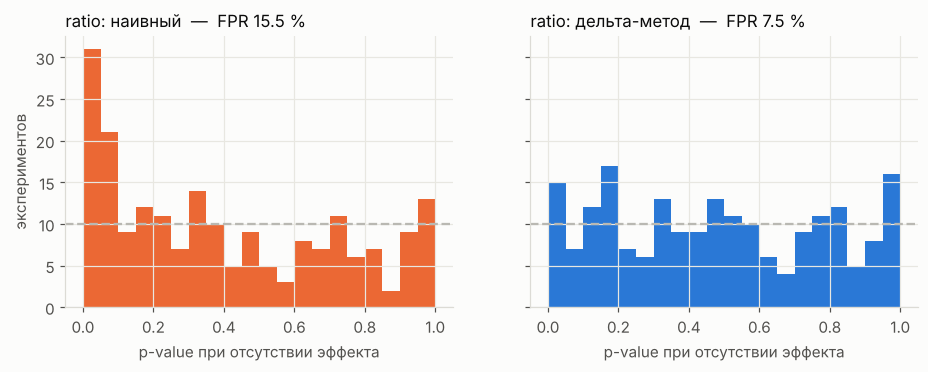

In [9]:
from ablab.population import simulate_period

N_AA, N_SMALL = 200, 20_000
aa = []
for _ in range(N_AA):
    p = sample_population(N_SMALL, rng)
    pre, post = simulate_period(p, 28, rng), simulate_period(p, 14, rng)
    g = rng.permutation(N_SMALL) < N_SMALL // 2
    aa.append({
        "GMV: Welch": S.welch_ttest(post.gmv[~g], post.gmv[g]).pvalue,
        "GMV: CUPED, 3 ков.": S.cuped_multi(post.gmv[~g], post.gmv[g],
            np.c_[pre.gmv, pre.orders, pre.sessions][~g],
            np.c_[pre.gmv, pre.orders, pre.sessions][g])[0].pvalue,
        "ratio: дельта-метод": S.ratio_delta(post.orders[~g], post.sessions[~g],
                                             post.orders[g], post.sessions[g]).pvalue,
        "ratio: наивный": S.ratio_naive(post.orders[~g], post.sessions[~g],
                                        post.orders[g], post.sessions[g]).pvalue,
    })
aa = pd.DataFrame(aa)
half = 1.96 * np.sqrt(.05 * .95 / N_AA) * 100
print(f"{N_AA} A/A-экспериментов по {N_SMALL:,} пользователей; допустимая полоса: "
      f"5.0 ± {half:.1f} %\n")
print((100 * (aa < 0.05).mean()).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (m, col) in zip(axes, [("ratio: наивный", ORANGE), ("ratio: дельта-метод", BLUE)]):
    ax.hist(aa[m], bins=20, range=(0, 1), color=col)
    ax.axhline(N_AA / 20, ls="--", c=GREY, lw=1.5)
    ax.set_title(f"{m}  —  FPR {100 * (aa[m] < 0.05).mean():.1f} %", loc="left")
    ax.set_xlabel("p-value при отсутствии эффекта")
axes[0].set_ylabel("экспериментов")
plt.show()

Пунктир — уровень, на котором гистограмма была бы ровной. У дельта-метода она ровная,
у наивного — завал влево: тест систематически выдаёт слишком маленькие p-value, и каждое
седьмое решение «эффект есть» на самом деле случайность. На 1000 прогонах
(`results/validation.md`) — 13.9 % против 5.9 %.

## 7. Аддитивная витрина для BI

BI-инструмент агрегирует данные сам, поэтому в витрину кладутся **аддитивные** величины:
`gmv`, `orders`, `sessions`, `assigned_users`. Отношения (GMV на пользователя, конверсия)
считаются уже в BI формулой `SUM(gmv) / SUM(assigned_users)`.

Почему не положить готовое среднее: среднее от средних по дням не равно общему среднему,
если дни разного размера, а сумма сумм — равна. Поэтому агрегат, который будут резать
фильтрами, обязан быть аддитивным. Исключение — `active_users`: `COUNT(DISTINCT)`
не восстанавливается из суточных сумм, поэтому эта метрика кладётся в витрину готовой и
не суммируется по дням.

In [10]:
mart = run_sql(DB, ROOT / "sql" / "mart_daily.sql", experiment=EXPERIMENT)
MARTS = ROOT / "data" / "marts"
MARTS.mkdir(exist_ok=True)

mart.to_csv(MARTS / "mart_daily.csv", index=False, encoding="utf-8")
df.to_csv(MARTS / "mart_users.csv", index=False, encoding="utf-8")
pd.concat([res.assign(тип="метрика"), seg.assign(тип="сегмент")]).to_csv(
    MARTS / "mart_results.csv", index=False, encoding="utf-8")

print(f"строк в суточной витрине: {len(mart)}  ({mart.day.nunique()} дней × "
      f"{mart.variant.nunique()} варианта × {mart.platform.nunique()} платформы)")
for f in sorted(MARTS.glob("*.csv")):
    print(f"  {f.name:<20} {f.stat().st_size / 1024:>8.0f} КБ")
mart.head()

строк в суточной витрине: 84  (14 дней × 2 варианта × 3 платформы)
  mart_daily.csv              5 КБ
  mart_results.csv            2 КБ
  mart_users.csv           3075 КБ


,day,variant,platform,assigned_users,active_users,sessions,orders,buyers,gmv,gmv_cum
0,0,control,android,14955,6196,12080,403,379,975669.68,975669.68
1,0,control,ios,9082,3706,7253,239,228,519417.13,519417.13
2,0,control,web,5964,2463,4889,140,134,313343.73,313343.73
3,0,treatment,android,15085,6176,12052,470,441,998297.88,998297.88
4,0,treatment,ios,8962,3643,7031,270,251,684124.21,684124.21


## 8. Дашборд

Что на нём должно быть, чтобы продакт принял решение, не читая ноутбук: показатель и его
доверительный интервал, проверка валидности, динамика по дням и разрезы. Чего быть не должно —
кумулятивной кривой как основания для решения: смотреть на неё каждый день и останавливать
тест, когда линии разошлись, значит проводить множественные сравнения во времени. Поэтому
подпись под графиком прямо на это указывает.

Оформление: один цвет на вариант, подписи прямо у линий вместо легенды там, где это возможно,
ноль как опорная линия на графике эффектов.

variant
control      30001
treatment    29999


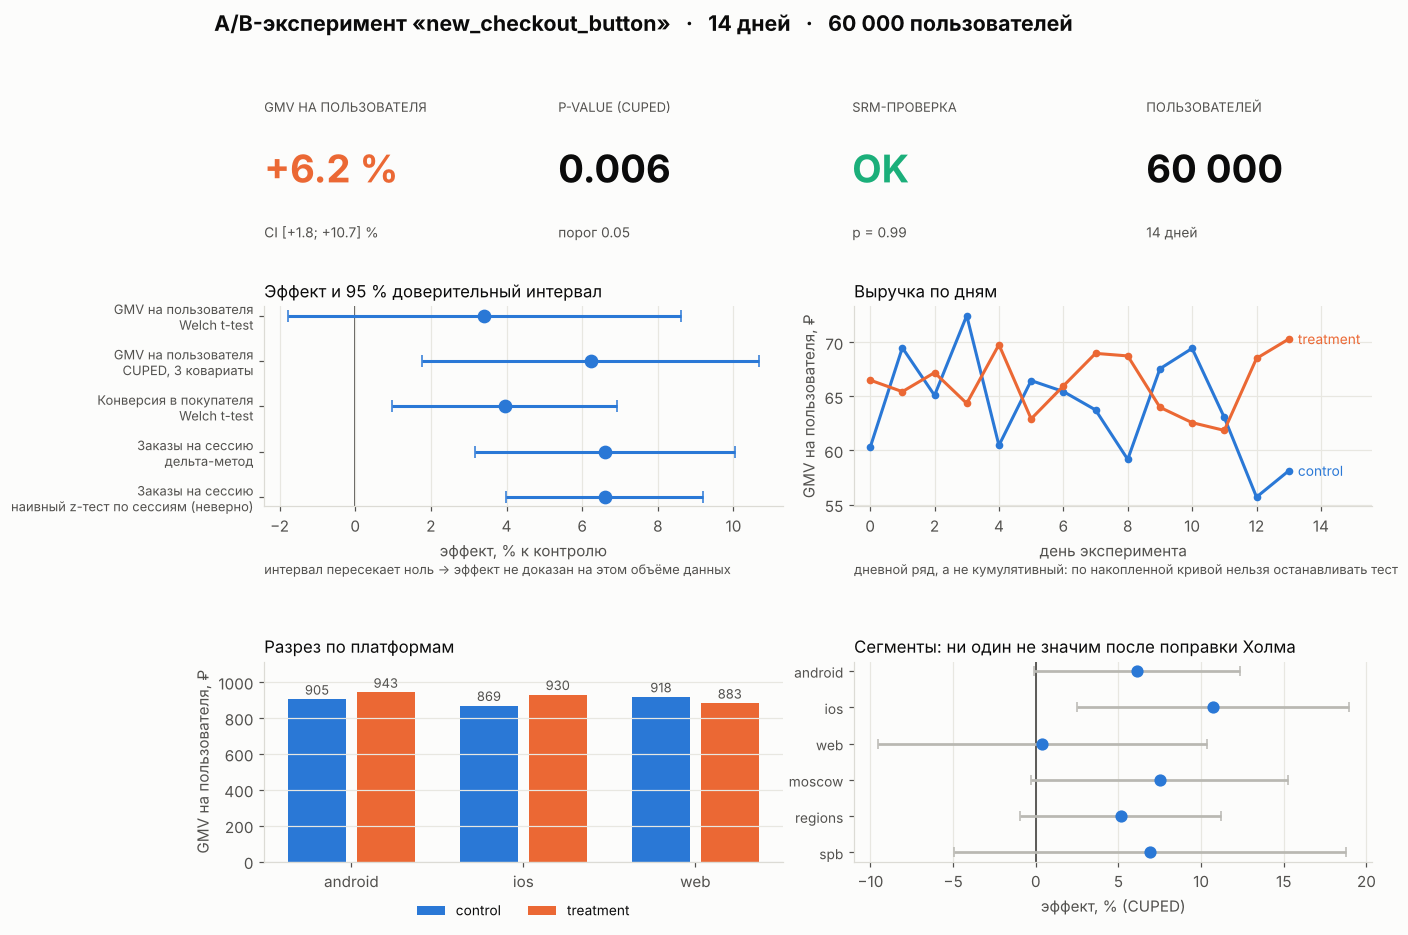

In [11]:
# размер группы берётся один раз на (вариант, платформу) и суммируется по платформам:
# в суточной витрине assigned_users повторяется в каждом дне, суммировать его по дням нельзя
group_size = (mart.groupby(["variant", "platform"]).assigned_users.first()
                  .groupby("variant").sum())
tot = mart.groupby(["variant", "day"], as_index=False).agg(gmv=("gmv", "sum"))
tot["gmv_per_user"] = tot.gmv / tot.variant.map(group_size)
COLOR = {"control": BLUE, "treatment": ORANGE}
print(group_size.to_string())

main = res[res["метод"].isin(["Welch t-test", "CUPED, 3 ковариаты", "дельта-метод",
                              "наивный z-тест по сессиям (неверно)"])].copy()
main["label"] = main["метрика"] + "\n" + main["метод"]

fig = plt.figure(figsize=(13, 9.0))
outer = fig.add_gridspec(2, 1, height_ratios=[0.26, 1.0], hspace=0.18)
kpi_gs = outer[0].subgridspec(1, 4, wspace=0.3)
gs = outer[1].subgridspec(2, 4, hspace=0.78, wspace=0.32)

kpi = [("GMV на пользователя", f"{100 * r3.effect / base_gmv:+.1f} %", f"CI [{100 * r3.ci_low / base_gmv:+.1f}; {100 * r3.ci_high / base_gmv:+.1f}] %", ORANGE),
       ("p-value (CUPED)", f"{r3.pvalue:.3f}", "порог 0.05", INK),
       ("SRM-проверка", "OK", f"p = {p_srm:.2f}", "#1baf7a"),
       ("Пользователей", f"{len(df):,}".replace(",", " "), f"{EXP_DAYS} дней", INK)]
for i, (title, value, sub, col) in enumerate(kpi):
    ax = fig.add_subplot(kpi_gs[0, i]); ax.axis("off")
    ax.text(0, 1.0, title.upper(), fontsize=8.5, color=INK2, va="top")
    ax.text(0, 0.52, value, fontsize=25, color=col, va="center", fontweight="bold")
    ax.text(0, 0.02, sub, fontsize=9, color=INK2, va="bottom")

ax = fig.add_subplot(gs[0, :2])
y = np.arange(len(main))[::-1]
ax.errorbar(main["эффект, %"], y,
            xerr=[main["эффект, %"] - main["CI 95 % низ"], main["CI 95 % верх"] - main["эффект, %"]],
            fmt="o", ms=8, lw=2, color=BLUE, ecolor=BLUE, capsize=4, zorder=3)
ax.axvline(0, color=INK2, lw=1.2, zorder=1)
ax.set_yticks(y); ax.set_yticklabels(main["label"], fontsize=8.5)
ax.set_xlabel("эффект, % к контролю"); ax.grid(axis="y", visible=False)
ax.set_title("Эффект и 95 % доверительный интервал", loc="left")
ax.text(0, -0.34, "интервал пересекает ноль -> эффект не доказан на этом объёме данных",
        transform=ax.transAxes, fontsize=8.5, color=INK2)

ax = fig.add_subplot(gs[0, 2:])
for v, g in tot.groupby("variant"):
    ax.plot(g.day, g.gmv_per_user, color=COLOR[v], marker="o", ms=4)
    ax.annotate(v, (g.day.iloc[-1], g.gmv_per_user.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", color=COLOR[v], fontsize=9, va="center")
ax.set_xlabel("день эксперимента"); ax.set_ylabel("GMV на пользователя, ₽")
ax.set_xlim(-0.5, EXP_DAYS + 1.6)
ax.set_title("Выручка по дням", loc="left")
ax.text(0, -0.34, "дневной ряд, а не кумулятивный: по накопленной кривой нельзя "
        "останавливать тест", transform=ax.transAxes, fontsize=8.5, color=INK2)

ax = fig.add_subplot(gs[1, :2])
plat = (mart.groupby(["platform", "variant"], as_index=False)
            .agg(gmv=("gmv", "sum"), users=("assigned_users", "first")))
plat["gpu"] = plat.gmv / plat.users
w, xs = 0.40, np.arange(plat.platform.nunique())
for k, (v, g) in enumerate(plat.groupby("variant")):
    vals = g.sort_values("platform").gpu.values
    pos = xs + (k - 0.5) * w
    ax.bar(pos, vals, width=w - 0.06, color=COLOR[v], label=v)
    for x_, y_ in zip(pos, vals):
        ax.annotate(f"{y_:,.0f}".replace(",", " "), (x_, y_), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(xs); ax.set_xticklabels(sorted(plat.platform.unique()))
ax.set_ylabel("GMV на пользователя, ₽"); ax.grid(axis="x", visible=False)
ax.set_ylim(0, plat.gpu.max() * 1.18)
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper center",
          bbox_to_anchor=(0.5, -0.14))
ax.set_title("Разрез по платформам", loc="left")

ax = fig.add_subplot(gs[1, 2:])
ys = np.arange(len(seg))[::-1]
ax.errorbar(seg["эффект, %"], ys,
            xerr=[seg["эффект, %"] - seg["CI низ"], seg["CI верх"] - seg["эффект, %"]],
            fmt="o", ms=7, lw=1.8, color=BLUE, ecolor=GREY, capsize=3, zorder=3)
ax.axvline(0, color=INK2, lw=1.2)
ax.set_yticks(ys); ax.set_yticklabels(seg["сегмент"], fontsize=9)
ax.set_xlabel("эффект, % (CUPED)"); ax.grid(axis="y", visible=False)
ax.set_title("Сегменты: ни один не значим после поправки Холма", loc="left")

fig.suptitle(f"A/B-эксперимент «{EXPERIMENT}»   ·   {EXP_DAYS} дней   ·   "
             f"{len(df):,} пользователей".replace(",", " "),
             fontsize=14, fontweight="bold", x=0.09, ha="left", y=0.97)
(ROOT / "figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "figures" / "dashboard.png", dpi=140, bbox_inches="tight", facecolor=SURF)
plt.show()

## 9. Решение

**Раскатывать.** Первичная метрика, зафиксированная до старта (GMV на пользователя, CUPED
с тремя ковариатами), даёт значимый прирост; `SRM` в норме; ratio-метрика подтверждает
направление на корректном дельта-методе. Сегментные различия в решение не входят: после
поправки на множественность ни одно не значимо.

Что осталось за рамками и было бы следующим шагом:

* **последовательное тестирование.** Сейчас решение принимается один раз, в конце. Если
  подглядывать ежедневно, FPR растёт с 5 % примерно до 20 % за две недели — нужен mSPRT или
  group sequential design с альфа-спендингом.
* **сетевые эффекты.** На маркетплейсе покупатели конкурируют за один и тот же товар, и
  SUTVA нарушается: тест-группа «забирает» предложение у контрольной. Лечится switchback-
  или кластерными экспериментами.

Витрины выгружены в `data/marts/`. Как построить из них дашборд в Yandex DataLens —
в [`docs/datalens.md`](../docs/datalens.md).